# Getting started with minigeo

minigeo describes simple 3D geometry in Python — points, lines, boxes, cylinders — and draws it
with matplotlib, as SVG, or interactively with plotly. This notebook walks through the main ideas:

1. geometries and transforms
2. a shape's own axes x', y', z'
3. anchors: named points, as in TikZ
4. scenes and styles, and the three backends

In [1]:
import numpy as np

from minigeo import Scene, Style
from minigeo.geometry import (
    BaseAxis,
    BaseBox,
    BaseCircle,
    BaseCone,
    BaseCylinder,
    BaseLine,
    BasePoint,
    BasePolygon,
    BaseRectangle,
    Transform,
)
from minigeo.groups import GeometryGroup

## 1. Geometries

Every geometry has vertices in world coordinates. Shapes are created at a position, with
dimensions whose meaning depends on the shape.

In [2]:
point = BasePoint([1, 1, 1])
line = BaseLine([0, 0, 0], [2, 1, 0])
axis = BaseAxis(direction=[0, 0, 1], position=[1, 0, 0])
box = BaseBox([0, 0, 0], dimensions=[1, 2, 3])  # width (x), length (y), height (z)
cylinder = BaseCylinder([2, 0, 0], dimensions=[0.5, 2])  # radius, height; stands on its position
cone = BaseCone([4, 0, 0], dimensions=[0.5, 0.2, 1])  # bottom radius, top radius, height
circle = BaseCircle([0, 3, 0], dimensions=[0.5])
rectangle = BaseRectangle([2, 3, 0], dimensions=[1, 0.5])
triangle = BasePolygon([4, 3, 0], [[0, 0, 0], [1, 0, 0], [0, 1, 0]])  # corners relative to the position

for geometry in (point, line, axis, cylinder, cone, circle):
    print(geometry)

BasePoint at [1 1 1]
BaseLine from [0 0 0] to [2 1 0]
BaseAxis at [1. 0. 0.] with direction [0. 0. 1.]
BaseCylinder at [2. 0. 1.] with radius 0.5 and height 2.0
BaseCone at [4.  0.  0.5] with radii 0.5 (bottom), 0.2 (top) and height 1.0
BaseCircle at [0. 3. 0.] with radius 0.5


## 2. Transforms

A `Transform` is a 4×4 matrix built step by step. `transform @ shape` applies it to the shape
(in place) and returns the shape; `t1 @ t2` combines two transforms (`t2` first).

In [3]:
p = BasePoint([1, 0, 0])
Transform().translate([0, 0, 2]) @ p
print("moved up:", p.position)

quarter_turn = Transform().rotate("z", 90)
print("turned:  ", (quarter_turn @ BasePoint([1, 0, 0])).position.round(6))

move_then_turn = quarter_turn @ Transform().translate([1, 0, 0])
print("combined:", (move_then_turn @ BasePoint([0, 0, 0])).position.round(6))

moved up: [1. 0. 2.]
turned:   [0. 1. 0.]
combined: [0. 1. 0.]


Rotations turn around an axis through the origin. With `about=` the axis passes through
another point instead, for example the shape's own center:

In [4]:
box = BaseBox([5, 0, 0], dimensions=[2, 1, 1])
box.rotate("z", 90)
print("around the origin:", box.center.round(6))

box = BaseBox([5, 0, 0], dimensions=[2, 1, 1])
box.rotate("z", 90, about="center")
print("around its center:", box.center.round(6))

around the origin: [0. 5. 0.]
around its center: [5. 0. 0.]


## 3. A shape's own axes

Every shape has its own axes x', y', z'. They start aligned with x, y, z and turn with the
shape. Rotations can use them by name, e.g. `"x'"`:

In [5]:
box = BaseBox([0, 0, 0], dimensions=[2, 1, 0.5])
box.rotate("z", 60, about="center")
box.rotate("x'", 35, about="center")  # tilt around the box's own long axis
print(box.axes.round(3))  # rows: x', y', z' in world coordinates

[[ 0.5    0.866  0.   ]
 [-0.709  0.41   0.574]
 [ 0.497 -0.287  0.819]]


`frame=True` draws a shape's own axes as arrows (x′ red, y′ green, z′ blue), and
`scene.add_frame()` the world axes. Frames are looked up when the scene is drawn, so they turn
with the shape. A scene on the last line of a cell shows itself as an SVG drawing:

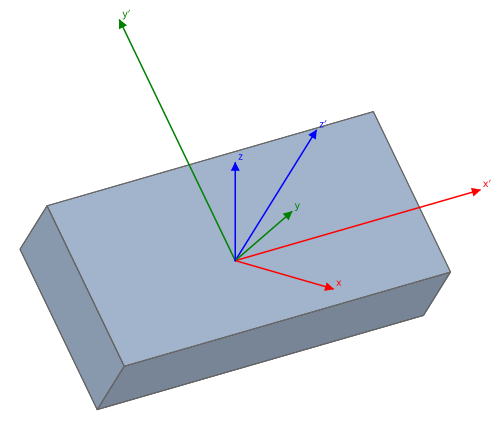

In [6]:
scene = Scene()
scene.add(box, fill="lightsteelblue", frame=True)
scene.add_frame(length=0.6)  # the world axes x, y, z at the origin, for comparison
scene

## 4. Anchors

Anchors are named points on a geometry, as in TikZ. For shapes and groups they combine
left/right (x'), front/back (y') and bottom/top (z'); lines use `start`, `midway`, `end`,
`near start` and `near end`. Anchors move and turn with the geometry.

`place(anchor, at=point)` moves a geometry so that one of its anchors sits on a point:

In [7]:
table = BaseBox([0, 0, 0], dimensions=[2, 1, 0.1], anchor="bottom")
print("top of the table:     ", table.anchor("top"))
print("a corner:             ", table.anchor("top front left"))

book = BaseBox([0, 0, 0], dimensions=[0.5, 0.35, 0.06])
book.rotate("z'", 20, about="center")
book.place("bottom", at=table.anchor("top"))
print("book lies on the table:", book.anchor("bottom"))

edge = BaseLine(table.anchor("top front left"), table.anchor("top front right"))
print("three quarters along: ", edge.anchor("near end"))

top of the table:      [0.  0.  0.1]
a corner:              [-1.  -0.5  0.1]
book lies on the table: [0.  0.  0.1]
three quarters along:  [ 0.5 -0.5  0.1]


## 5. Scenes and styles

Geometry does not know how it is drawn. A `Scene` collects geometries with their `Style`
(fill, stroke, opacity, line width, dashes, arrows, labels). `scene.add` returns the
geometry, so creating and adding fit on one line. Styles combine with `|`.

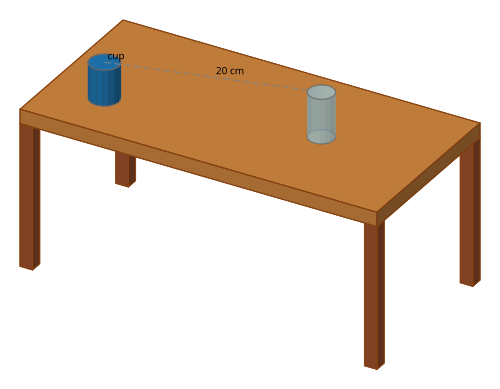

In [8]:
wood = Style(fill="peru", stroke="saddlebrown")

scene = Scene()
table = scene.add(BaseBox([0, 0, 0.8], dimensions=[2, 1, 0.08], anchor="bottom"), wood)
for corner in ("front left", "front right", "back left", "back right"):
    leg = BaseBox(table.anchor(f"bottom {corner}"), dimensions=[0.07, 0.07, 0.8], anchor=f"top {corner}")
    scene.add(leg, wood | Style(fill="sienna"))

cup = scene.add(BaseCylinder(table.anchor("top front left") + [0.3, 0.3, 0], dimensions=[0.08, 0.2]), fill="C0")
scene.label(cup, "cup", at="top")
glass = scene.add(BaseCylinder(table.anchor("top") + [0.4, 0, 0], dimensions=[0.07, 0.25]), fill="lightblue", opacity=0.5)
scene.add(BaseLine(cup.anchor("top"), glass.anchor("top")), stroke="gray", dash="dashed", label="20 cm", label_at="midway")
scene

### The same scene with the three backends

* **SVG** (above, and `scene.render("svg")`): a vector drawing like a TikZ picture; `.save("scene.svg")`.
* **matplotlib**: a 3D axes you can combine with other plots; the view can be rotated in interactive backends.
* **plotly**: interactive in the browser and in Jupyter; `.write_html("scene.html")` saves it.

All three take the same view options: `elev`, `azim` and `vertical_axis`.

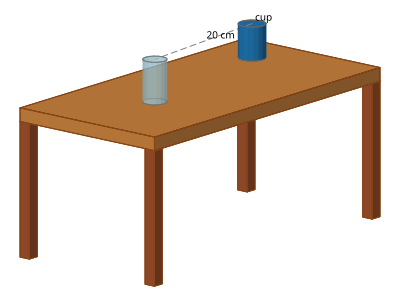

In [9]:
scene.render("svg", elev=15, azim=40, width=400)

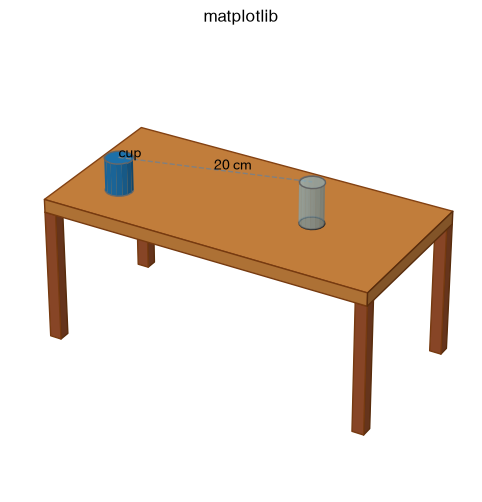

In [10]:
import matplotlib.pyplot as plt

ax = scene.render("matplotlib", show_axes=False)
ax.set_title("matplotlib")
plt.show()

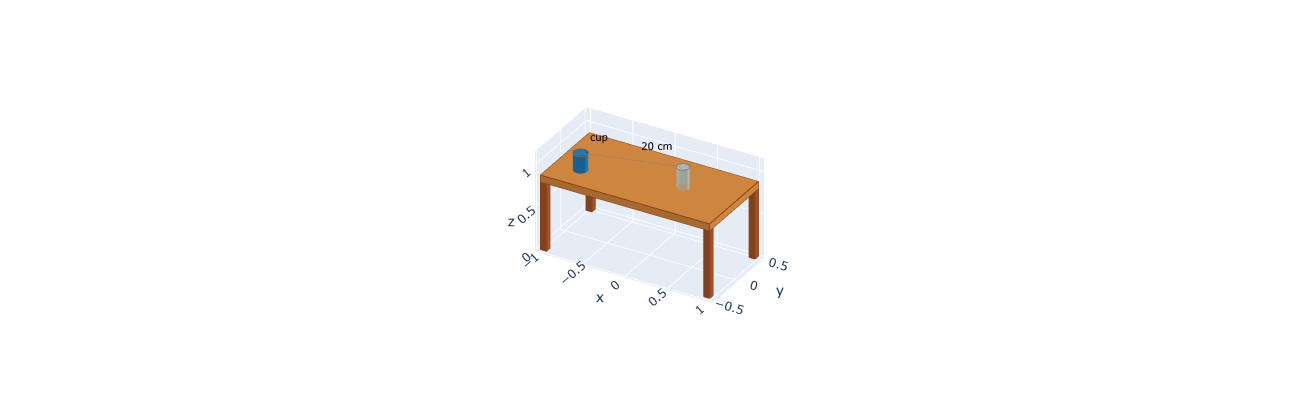

In [11]:
scene.render("plotly", height=400)

## 6. Understanding a transform

Seeing a shape before and after a transform helps to understand it. The original box is drawn
transparent, the rotated copy solid, and the rotation axis as an arrow.

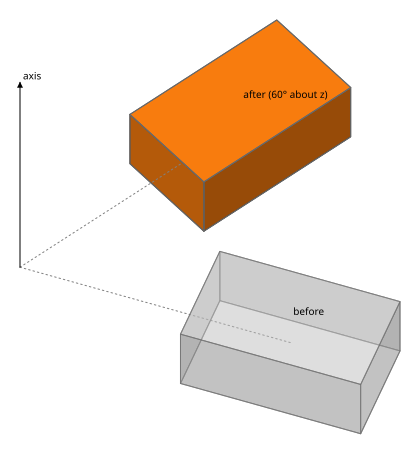

In [12]:
before = BaseBox([1.5, 0, 0], dimensions=[1, 0.6, 0.4])
after = BaseBox([1.5, 0, 0], dimensions=[1, 0.6, 0.4])
rotation_axis = np.array([0, 0, 1])
after.rotate(rotation_axis, 60, about=[0, 0, 0])

scene = Scene()
scene.add(before, fill="lightgray", opacity=0.4, label="before", label_at="top")
scene.add(after, fill="C1", label="after (60° about z)", label_at="top")
scene.add(BaseAxis(rotation_axis, length=1.5), stroke="black", label="axis", label_at="end")
scene.add(BaseLine([0, 0, 0], before.center), stroke="gray", dash="dotted")
scene.add(BaseLine([0, 0, 0], after.center), stroke="gray", dash="dotted")
scene.render("svg", elev=50, azim=-70, width=420)

A sequence of small pictures shows how a rotation develops — here a box turning about its
own tilted axis, step by step:

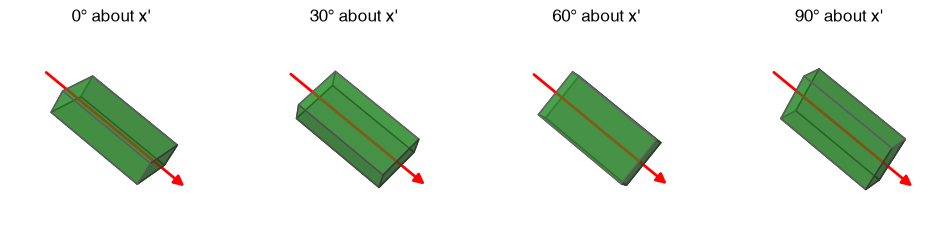

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), subplot_kw={"projection": "3d"})
box = BaseBox([0, 0, 0], dimensions=[1.2, 0.6, 0.3])
box.rotate("y", 30, about="center")
for step, ax in enumerate(axes):
    scene = Scene()
    scene.add(box, fill="C2", opacity=0.6)  # translucent, so the axis shows through
    scene.add(BaseAxis(box.axes[0], position=box.center - box.axes[0], length=2), stroke="red", line_width=2)
    scene.render("matplotlib", ax=ax, show_axes=False, elev=20, azim=-60)
    ax.set_title(f"{30 * step}° about x'")
    box.rotate("x'", 30, about="center")
plt.show()